#Exercise 3 - Advanced topics in ML
author: Seyedeh Sharareh Mirzargar

Self-supervised learning using contrasive learning in SimCLR framework
![photo](https://camo.githubusercontent.com/5ab5e0c019cdd8129b4450539231f34dc028c0cd64ba5d50db510d1ba2184160/68747470733a2f2f312e62702e626c6f6773706f742e636f6d2f2d2d764834504b704539596f2f586f3461324259657276492f414141414141414146704d2f766146447750584f79416f6b4143385868383532447a4f67457332324e68625877434c63424741735948512f73313630302f696d616765342e676966)

Mounting my Google drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Libraries

In [2]:
import os
import numpy as np
from torch.utils.data import Dataset, DataLoader, Subset, random_split
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torch.optim as optim
import torchvision.transforms.functional as TF

import matplotlib.pyplot as plt
import PIL.Image as Image
import pandas as pd
import random


Showing the device

In [3]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("you are running on "+str(device))

you are running on cuda:0


Here we implement the dataset class, create the unlabaled, training, validation and test sets and the dataloaders.

In [4]:
class LabeledDataset(Dataset):
    def __init__(self, folder_path, phase='train', transform=None):
        super(LabeledDataset, self).__init__()
        self.phase = phase
        if self.phase == 'train':
            file_path = os.path.join(folder_path, 'train_32x32_500_label.npz')
        elif self.phase == 'val':
            file_path = os.path.join(folder_path, 'test_32x32_2000_label.npz')
        elif self.phase == 'test':
            file_path = os.path.join(folder_path, 'test_32x32_competition.npy')
        elif self.phase == 'unlabeled':
            file_path = os.path.join(folder_path, 'train_32x32_unlabel.npy')
        else:
            print('Unrecognized phase')
        data_load = np.load(file_path)
        
        if self.phase != 'test' and self.phase != 'unlabeled':
            self.dataset = data_load['img']
            self.labels = data_load['label'].astype('int64')
        
        else:
            self.dataset = data_load
            
        self.transform = transform
        
    def __getitem__(self, index): 
        img_index = Image.fromarray(self.dataset[index,:])
        if self.phase != 'test' and self.phase != 'unlabeled':
            
            return self.transform(img_index), self.labels[index,0]
        elif self.phase == 'unlabeled':
          
          return self.transform(img_index),self.transform(img_index)
        else:
            
            return self.transform(img_index)

    def __len__(self):
        return self.dataset.shape[0]

#simCLR
In this exercise I have use **SimCLR** which is a framework for contrastive learning of visual representations. It learns representations by maximizing agreement between differently augmented views of the same data example via a contrastive loss in the latent space. This implementation is done by using the following resouces and adapting them to the given dataset.

SimCLR paper: https://arxiv.org/pdf/2002.05709.pdf

simCLR short video: https://www.youtube.com/watch?v=YZgeWsuyRH8&ab_channel=AIBites

simCLR pytorch implementation: https://github.com/ae-foster/pytorch-simclr


creadit for the images: https://amitness.com/2020/03/illustrated-simclr/

This image gives an overview of the main modules of the simCLR framework; which is:


*   Data augmentation 
*   Encoder 
*   Projection head 


![photo](https://amitness.com/images/simclr-general-architecture.png)


##augmentation

A random transformation function T that takes an image and applies a random combination of: 
*   transforms.RandomResizedCrop(img_size, interpolation=Image.BICUBIC)
*   transforms.RandomHorizontalFlip()
*   ColourDistortion(s=0.5)


![augmentation](https://amitness.com/images/simclr-random-transformation-function.gif)

In [5]:
from PIL import ImageFilter
from torchvision import transforms


def ColourDistortion(s=1.0):
    # s is the strength of color distortion.
    color_jitter = transforms.ColorJitter(0.8*s, 0.8*s, 0.8*s, 0.2*s)
    rnd_color_jitter = transforms.RandomApply([color_jitter], p=0.8)
    rnd_gray = transforms.RandomGrayscale(p=0.2)
    color_distort = transforms.Compose([rnd_color_jitter, rnd_gray])
    return color_distort


def BlurOrSharpen(radius=2.):
    blur = GaussianBlur(radius=radius)
    full_transform = transforms.RandomApply([blur], p=.5)
    return full_transform


class ImageFilterTransform(object):

    def __init__(self):
        raise NotImplementedError

    def __call__(self, img):
        return img.filter(self.filter)


class GaussianBlur(ImageFilterTransform):

    def __init__(self, radius=2.):
        self.filter = ImageFilter.GaussianBlur(radius=radius)


class Sharpen(ImageFilterTransform):

    def __init__(self):
        self.filter = ImageFilter.SHARPEN

##Resnet
In simCLR paper, the authors used ResNet-50 architecture as the ConvNet encoder. Its input is two augmneted image of the same object and its output is representation, 'h_i' and 'h_j'.

Resnet: https://arxiv.org/abs/1512.03385

Resnet-50 in Pytorch: https://github.com/pytorch/vision/blob/master/torchvision/models/resnet.py

The following image shows the ResNet50 of the simCLR paper, whose input is 243x243 RGB images. In this exercise, I have adapted the Resnet50 network to receive 32x32 RGB images 

![An image](https://amitness.com/images/simclr-paper-encoder.png)



In [6]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models.resnet import BasicBlock, Bottleneck, conv1x1

class Stem(nn.Module):
    def __init__(self):
        super(Stem, self).__init__()
        self.in_planes = 64
        self.conv1 = nn.Conv2d(3, self.in_planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(self.in_planes)

    def forward(self, inputs):
        return F.relu(self.bn1(self.conv1(inputs)))

class ResNet(nn.Module):

    def __init__(self, block, layers, stem, num_classes=None, zero_init_residual=False,
                 groups=1, width_per_group=64, replace_stride_with_dilation=None,
                 norm_layer=None):
        super(ResNet, self).__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 64
        self.dilation = 1
        if replace_stride_with_dilation is None:

            replace_stride_with_dilation = [False, False, False]
        if len(replace_stride_with_dilation) != 3:
            raise ValueError("replace_stride_with_dilation should be None "
                             "or a 3-element tuple, got {}".format(replace_stride_with_dilation))
        self.groups = groups
        self.stem = stem()
        self.base_width = width_per_group
        
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2,
                                       dilate=replace_stride_with_dilation[0])
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2,
                                       dilate=replace_stride_with_dilation[1])
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2,
                                       dilate=replace_stride_with_dilation[2])
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        if num_classes is not None:
            self.fc = nn.Linear(512 * block.expansion, num_classes)
        else:
            self.fc = None

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, Bottleneck):
                    nn.init.constant_(m.bn3.weight, 0)
                elif isinstance(m, BasicBlock):
                    nn.init.constant_(m.bn2.weight, 0)

        self.representation_dim = 512 * block.expansion

    def _make_layer(self, block, planes, blocks, stride=1, dilate=False):
        norm_layer = self._norm_layer
        downsample = None
        previous_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                norm_layer(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample, self.groups,
                            self.base_width, previous_dilation, norm_layer))
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation,
                                norm_layer=norm_layer))

        return nn.Sequential(*layers)

    def _forward_impl(self, x):
        
        x = self.stem(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        if self.fc:
            x = self.fc(x)

        return x

    def forward(self, x):
        return self._forward_impl(x)


def ResNet18(**kwargs):
    return ResNet(BasicBlock, [2,2,2,2], **kwargs)


def ResNet34(**kwargs):
    return ResNet(BasicBlock, [3,4,6,3], **kwargs)


def ResNet50(**kwargs):
    return ResNet(Bottleneck, [3,4,6,3], **kwargs)

##Projection head
The representations 'h_i' and 'h_j' of the two augmented images are then passed through a series of non-linear (Dense -> Relu -> Dense) layers to apply non-linear transformation and project it into a representation 'z_i' and 'z_j'

![picture](https://amitness.com/images/simclr-projection-head-component.png)


In [7]:
import torch
from torch import nn


class LinearCritic(nn.Module):

    def __init__(self, latent_dim, temperature=1.):
        super(LinearCritic, self).__init__()
        self.temperature = temperature
        self.projection_dim = 128
        self.w1 = nn.Linear(latent_dim, latent_dim, bias=False)
        self.bn1 = nn.BatchNorm1d(latent_dim)
        self.relu = nn.ReLU()
        self.w2 = nn.Linear(latent_dim, self.projection_dim, bias=False)
        self.bn2 = nn.BatchNorm1d(self.projection_dim, affine=False)
        self.cossim = nn.CosineSimilarity(dim=-1)

    def project(self, h):
        return self.bn2(self.w2(self.relu(self.bn1(self.w1(h)))))

    def forward(self, h1, h2):
        z1, z2 = self.project(h1), self.project(h2)
        sim11 = self.cossim(z1.unsqueeze(-2), z1.unsqueeze(-3)) / self.temperature
        sim22 = self.cossim(z2.unsqueeze(-2), z2.unsqueeze(-3)) / self.temperature
        sim12 = self.cossim(z1.unsqueeze(-2), z2.unsqueeze(-3)) / self.temperature
        d = sim12.shape[-1]
        sim11[..., range(d), range(d)] = float('-inf')
        sim22[..., range(d), range(d)] = float('-inf')
        raw_scores1 = torch.cat([sim12, sim11], dim=-1)
        raw_scores2 = torch.cat([sim22, sim12.transpose(-1, -2)], dim=-1)
        raw_scores = torch.cat([raw_scores1, raw_scores2], dim=-2)
        targets = torch.arange(2 * d, dtype=torch.long, device=raw_scores.device)
        return raw_scores, targets

##training
An image is taken and random transformations are applied to it to get a pair of two augmented images (x1 and x2 in the code).


Each image in this pair is then passed through an encoder (Resnet 50) to get representations.

Then a non-linear fully connected layer (critic) is applied to get representations (representation1 and representation2). The task is to maximize the similarity between these two representations for the same image.

In the inital work they use large batch size (512) and very long epoch number (1000) using imageNet. In this exercise, due to limitations on the GPU memory and run time, I chose to use a batch size of 128 and an apoche number of 100
*   img size = 32
*   number of classes = 10
*   batch size = 128
*   number of epoch = 150
*   encoder = ResNet50
*   Aptimizer=Adam
*   Learning rate = 3e-4



In [8]:
img_size = 32
num_classes = 10
batch_size = 128

start_epoch = 0 
num_epochs = 150
lr_rate = 0.25 * (batch_size/256.0)
net = ResNet50(stem = Stem)
net = net.to(device)
momentum  = 0.9

In [9]:
def train(loader, epoch,encoder_optimizer,criterion):

    print('\nEpoch: %d' % epoch)
    net.train()
    critic.train()
    train_loss = 0

    t = tqdm(enumerate(unlabeled_loader), desc='Loss: **** ', total=len(unlabeled_loader), bar_format='{desc}{bar}{r_bar}')
    
    for batch_idx, inputs in t:

        x1, x2 = inputs
        x1, x2 = x1.to(device), x2.to(device)
        encoder_optimizer.zero_grad()
        representation1, representation2 = net(x1), net(x2)
        raw_scores, pseudotargets = critic(representation1, representation2)
        loss = criterion(raw_scores, pseudotargets)
        loss.backward()
        encoder_optimizer.step()

        train_loss += loss.item()
        t.set_description('Loss: %.3f ' % (train_loss / (batch_idx + 1)))
    return train_loss

##data preperation

In [10]:


transform_train = transforms.Compose([
        transforms.RandomResizedCrop(img_size, interpolation=Image.BICUBIC),
        transforms.RandomHorizontalFlip(),
        ColourDistortion(s=0.5),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])
transform_test = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

train_set = LabeledDataset('/content/drive/MyDrive/Google colab/ATML21/Ex3', phase='train', transform=transform_train)
val_set = LabeledDataset('/content/drive/MyDrive/Google colab/ATML21/Ex3', phase='val', transform=transform_test)
test_set = LabeledDataset('/content/drive/MyDrive/Google colab/ATML21/Ex3', phase='test', transform=transform_test)
unlabeled_set = LabeledDataset('/content/drive/MyDrive/Google colab/ATML21/Ex3', phase='unlabeled', transform=transform_train)


train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=2)
unlabeled_loader = DataLoader(unlabeled_set, batch_size=batch_size, shuffle=False, num_workers=2)

/usr/local/lib/python3.7/dist-packages/torchvision/transforms/transforms.py:804: UserWarning: Argument interpolation should be of type InterpolationMode instead of int. Please, use InterpolationMode enum.
  "Argument interpolation should be of type InterpolationMode instead of int. "


showing some samples of the dataset

Label: 7
Image shape: torch.Size([3, 32, 32])


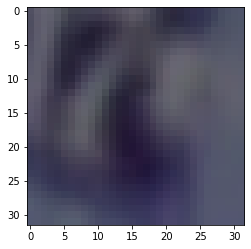

In [11]:
sample_image = train_set[0]
plt.imshow(sample_image[0].permute(1,2,0)*0.5 + 0.5)
print("Label:", sample_image[1])
print("Image shape:", sample_image[0].shape)

##Training on unlabeled datasets

The training has been done on the GPU cluster that is provided in this course (studi1, node01). It is because each epoch took ~7.5 minutes and for epoch=50, it took more than 6 hours. Unfortunately, on Google colab each epoch took more than 15 minutes and the training time would have been long than 12 hours

In [ ]:
import torch.optim as optim
from tqdm import tqdm

criterion = nn.CrossEntropyLoss()
critic = LinearCritic(latent_dim = net.representation_dim,temperature = 0.5).to(device)
base_optimizer = optim.SGD(list(net.parameters()) + list(critic.parameters()), lr=lr_rate, weight_decay=1e-6,
                           momentum=momentum)
encoder_optimizer = torch.optim.Adam(list(net.parameters()) + list(critic.parameters()), lr=3e-4)




if device == 'cuda':
    repr_dim = net.representation_dim
    net = torch.nn.DataParallel(net)
    net.representation_dim = repr_dim


for epoch in range(start_epoch, start_epoch + num_epochs):
    train_loss= train(unlabeled_loader, epoch,encoder_optimizer,criterion)

I will load the trained model to generate the predictions

In [14]:
PATH = "/content/drive/MyDrive/Seyedeh_Sharareh_Mirzargar_model_150_epoch.pth"
checkpoint = torch.load(PATH)
net.load_state_dict(checkpoint['model_state_dict'])
encoder_optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

#self-supervised transfer learning
Once the SimCLR model is trained on the contrastive learning task, it can be used for transfer learning. For this, the representations from the encoder are used instead of representations obtained from the projection head. These representations can be used for downstream tasks like classification.

![photo](https://amitness.com/images/simclr-downstream.png)

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm


def encode_train_set(clftrainloader, device, net):
    net.eval()

    store = []
    with torch.no_grad():
        t = tqdm(enumerate(clftrainloader), desc='Encoded: **/** ', total=len(clftrainloader),
                 bar_format='{desc}{bar}{r_bar}')
        for batch_idx, (inputs, targets) in t:
            inputs, targets = inputs.to(device), targets.to(device)
            representation = net(inputs)
            store.append((representation, targets))

            t.set_description('Encoded %d/%d' % (batch_idx, len(clftrainloader)))

    X, y = zip(*store)
    X, y = torch.cat(X, dim=0), torch.cat(y, dim=0)
    return X, y


def train_clf(X, y, representation_dim, num_classes, device, reg_weight=1e-3):
    print('\nL2 Regularization weight: %g' % reg_weight)

    criterion = nn.CrossEntropyLoss()
    n_lbfgs_steps = 500

    # Should be reset after each epoch for a completely independent evaluation
    clf = nn.Linear(representation_dim, num_classes).to(device)
    clf_optimizer = optim.LBFGS(clf.parameters())
    clf.train()

    t = tqdm(range(n_lbfgs_steps), desc='Loss: **** | Train Acc: ****% ', bar_format='{desc}{bar}{r_bar}')
    for _ in t:
        def closure():
            clf_optimizer.zero_grad()
            raw_scores = clf(X)
            loss = criterion(raw_scores, y)
            loss += reg_weight * clf.weight.pow(2).sum()
            loss.backward()

            _, predicted = raw_scores.max(1)
            correct = predicted.eq(y).sum().item()

            t.set_description('Loss: %.3f | Train Acc: %.3f%% ' % (loss, 100. * correct / y.shape[0]))

            return loss

        clf_optimizer.step(closure)

    return clf


def test(testloader, device, net, clf):
    
    predictions = np.array([])
    criterion = nn.CrossEntropyLoss()
    net.eval()
    clf.eval()
    total = 0
    with torch.no_grad():
        # t = tqdm(enumerate(testloader), total=len(testloader), desc='Loss: **** | Test Acc: ****% ',
        #          bar_format='{desc}{bar}{r_bar}')
        #for batch_idx, inputs in t:
        for inputs in testloader:    
            inputs = inputs.to(device)
            representation = net(inputs)
            raw_scores = clf(representation)

            _, predicted = raw_scores.max(1)
            if(device.type == 'cuda'):
              predictions = np.append(predictions, predicted.cpu().data.numpy())
            else:
              predictions = np.append(predictions, predicted)
    return predictions

Here, we first encode the images of the training dataset using 'encode_train_set' function. The outputs of this method is a representation of the training image(X). Its second output is the label of this training image.

Then the function 'train_clf' recives as input the representation, its lable, the dimension of the representation in the feature extractor network. In this step we train the linear projection heas on the smalle labled training set and use LBFGS optimizer.

Finally, we generate the predictions by the function 'test' which receives as input the competition dataset, and the trained feature extraction network and and the trained projection head.


In [16]:
X, y = encode_train_set(train_loader, device, net)
clf = train_clf(X, y, net.representation_dim, num_classes, device, reg_weight=1e-5)
predictions = test(test_loader, device, net, clf)
print(predictions)


Encoded: **/**           | 0/4 [00:00<?, ?it/s]
Encoded 0/4:           | 0/4 [00:00<?, ?it/s]  
Encoded 0/4: ██▌       | 1/4 [00:00<00:00,  3.25it/s]
Encoded 1/4: ██▌       | 1/4 [00:00<00:00,  3.25it/s]
Encoded 1/4: █████     | 2/4 [00:00<00:00,  3.32it/s]
Encoded 2/4: █████     | 2/4 [00:00<00:00,  3.32it/s]
Encoded 2/4: ███████▌  | 3/4 [00:00<00:00,  3.40it/s]
Encoded 3/4: ███████▌  | 3/4 [00:01<00:00,  3.40it/s]
Encoded 3/4: ██████████| 4/4 [00:01<00:00,  3.36it/s]

Loss: **** | Train Acc: ****%           | 0/500 [00:00<?, ?it/s]
Loss: 2.325 | Train Acc: 10.200% :           | 0/500 [00:00<?, ?it/s]


L2 Regularization weight: 1e-05



Loss: 2.298 | Train Acc: 11.400% :           | 0/500 [00:00<?, ?it/s]
Loss: 2.043 | Train Acc: 27.000% :           | 0/500 [00:00<?, ?it/s]
Loss: 1.869 | Train Acc: 39.800% :           | 0/500 [00:00<?, ?it/s]
Loss: 1.485 | Train Acc: 51.000% :           | 0/500 [00:00<?, ?it/s]
Loss: 1.110 | Train Acc: 68.600% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.989 | Train Acc: 71.400% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.738 | Train Acc: 77.200% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.638 | Train Acc: 79.600% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.615 | Train Acc: 80.600% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.598 | Train Acc: 82.600% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.546 | Train Acc: 83.600% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.478 | Train Acc: 86.000% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.432 | Train Acc: 86.600% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.341 | Train Acc: 89.200% :           | 0/500 [00:00<?, ?it/s]
Loss: 0.309 | Train

[5. 2. 1. ... 2. 6. 7.]


##Validation

In order to check that my model does not overfit, I have used the models that were trained for 60,100, and 150 epoch for validation and the highest validation accuracy belong to epoch = 150

In [17]:
def validation(val_loader, device, net, clf):
    
    predictions = np.array([])
    criterion = nn.CrossEntropyLoss()
    net.eval()
    clf.eval()
    total = 0
    accuracy = 0
    correct = 0
    with torch.no_grad():

        for data in val_loader:
        
            inputs, labels = data

            inputs = inputs.to(device)
            labels = labels.to(device)

            representation = net(inputs)
            raw_scores = clf(representation)

            _, predicted = raw_scores.max(1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = 100 * correct / total
    return accuracy

In [18]:
print(validation(val_loader, device, net, clf))

78.35


#prepare the submission file

Generating a csv file that contains the IDs and categories

In [ ]:
predictions = pd.DataFrame({
    "Id": np.arange(np.array(predictions).size),
    "Category": np.array(predictions)},
    dtype=np.int64)

In [ ]:
predictions.to_csv("/content/drive/MyDrive/Seyedeh_Sharareh_Mirzargar_predictions_epoch150_batch128.csv", index=False)